# 00 The project in one notebook

Can a gamma-ray burst's precursor tell a compact-binary merger from a collapsing massive star? This notebook goes through the whole
analysis once, in order, on one burst and then on the sample: the photons, the background, the Bayesian blocks and episodes, a
spectral fit, the join of E_peak with the variability timescale, Zhu et al.'s classification measured again, and whether the precursor's
own spectrum adds anything to it. Each step calls the code in `zhu/`, `grbtool/` and `instruments/`, or reads a table the batch saved
(`results/`, `shared/`); the numbered notebooks (08-27) have the details and the checks.

Run from `ignacio/` with the MVTEnv kernel. Steps 2-5 read GRB 211211A's GBM data (`python -m zhu.run prefetch` downloads it) and take a
few minutes; the rest read saved results and take seconds.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from instruments import fermi_gbm as G
from zhu import RESULTS
from zhu import laws as L
from zhu.catalogue import EPI_LINE, read_table_2026
from zhu.episodes import blocks_of, find_episodes
from zhu.features import collect, epi_summary

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
FIGURES = Path("figures")
NAME = "211211A"
table = read_table_2026()

## 1. The question

Short bursts (under about 2 s) were thought to come from neutron-star mergers and long ones from collapsars. GRB 211211A and GRB 230307A
broke that: both lasted tens of seconds, yet a kilonova followed each, so both were mergers. Both also had a precursor, a short pulse
before the main emission with a quiet gap after it. Zhu et al. (2025, 2026) built an index from such bursts,
EPI = log10[E_p,ME^2 / (T100,PE T100,QE1^(1/2) T_MVT,PE)], from the precursor's duration, the gap, the precursor's variability and the
main emission's peak energy; Type I (merger-like) bursts lie above about 6.2. The precursor's own spectrum is not in it. My question:
does the precursor's peak energy E_p,PE, or its contrast with the main emission E_p,PE/E_p,ME, add anything to what EPI already knows?

## 2. One burst from the photons: GRB 211211A

GBM records every photon (time-tagged events): its arrival time to 2 microseconds and one of 128 energy channels, in each of 12 NaI
(8 keV-1 MeV) and 2 BGO (0.2-40 MeV) detectors. The burst is set up exactly as the batch does it (`fermi_gbm.burst`): the NaI detectors
of the GBM catalogue and the BGO on their side.

NaI: ['n2', 'na'] | all detectors fitted: ['n2', 'na', 'b0'] | Zhu et al.'s time bin: 0.004 s | flags: none


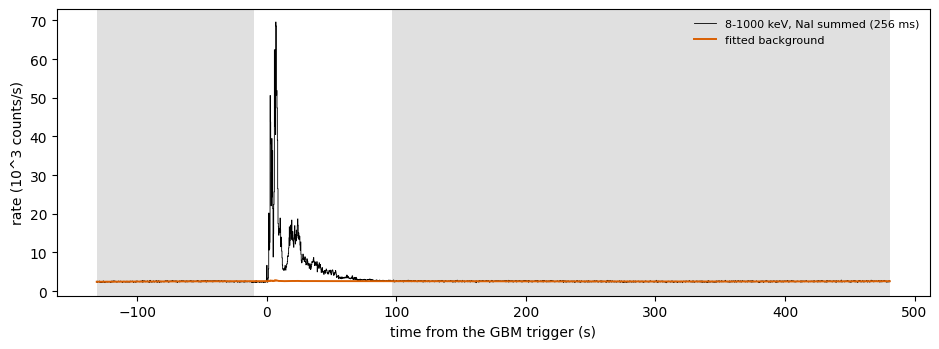

In [2]:
gbm, row, flags = G.burst(NAME)
print("NaI:", gbm.nai, "| all detectors fitted:", gbm.detectors, "| Zhu et al.'s time bin:", row.Tres, "s | flags:", flags or "none")
whole = G.light_curve(gbm, 0.256, span=(gbm.bkg_windows[0][0], gbm.bkg_windows[-1][1]))
t = 0.5 * (whole.edges[1:] + whole.edges[:-1])
fig, ax = plt.subplots(figsize=(9.5, 3.6))
for a, b in gbm.bkg_windows:
    ax.axvspan(a, b, color="0.88", lw=0)
ax.step(t, whole.counts / whole.exposure / 1e3, where="mid", lw=0.6, color="k", label="8-1000 keV, NaI summed (256 ms)")
ax.plot(t, whole.background / whole.exposure / 1e3, color="#d95f02", lw=1.4, label="fitted background")
ax.set_xlabel("time from the GBM trigger (s)"); ax.set_ylabel("rate (10^3 counts/s)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "00_light_curve.png", dpi=140); plt.show()

## 3. The background

The background is a polynomial in time, fitted separately to every detector and energy channel over the shaded intervals before and after
the burst (`zhu.background`, as in every notebook since 05). The intervals must keep clear of all the emission: the light curve is first
cut into blocks at 1.024 s and any block 5 sigma above the background pushes the intervals away, and before the burst the search is done
again at 64 ms, where a short precursor 4 sigma above the background counts as emission too (a half-second precursor is diluted in 1 s
bins). The orange line is that polynomial summed over the detectors and the band.

## 4. Bayesian blocks and the episodes

Bayesian blocks (Scargle et al. 2013) cut the light curve into pieces of constant rate, each change of rate kept only if the Poisson
likelihood gains more than a penalty set by the false-alarm probability p0 = 0.05. Zhu et al.'s rules then read the blocks: the precursor
(PE) is emission before a quiet episode (QE1, one block of at least 8 bins at the background level), and the main emission (ME) follows.
The rule is written out in `zhu/episodes.py` (mode zhu2026); here it runs at their time bin for this burst.

In [3]:
lc = G.light_curve(gbm, row.Tres)
blocks = blocks_of(lc)
found = find_episodes(lc, blocks, mode="zhu2026", burst=NAME)
d = found.durations()
keys = ["T100_PE", "T100_QE1", "T100_ME", "TMVT_PE"]
print(len(blocks), "blocks; the rule:", "; ".join(found.reasons[:3]))
pd.DataFrame({"ours (s)": [d[k] for k in keys], "Zhu et al. 2026 (s)": table.loc[NAME, keys].values}, index=keys).round(3)

247 blocks; the rule: qe2: first dip after the main peak of 385 bins at 0.036 of the peak, then x2.1; qe1: dip 1 of 1 in longest-first order, 173 bins at -0.16 per bin; QE at the background and PE counts below the ME's


,ours (s),Zhu et al. 2026 (s)
T100_PE,0.424,0.424
T100_QE1,0.692,0.692
T100_ME,11.236,11.236
TMVT_PE,0.014,0.014


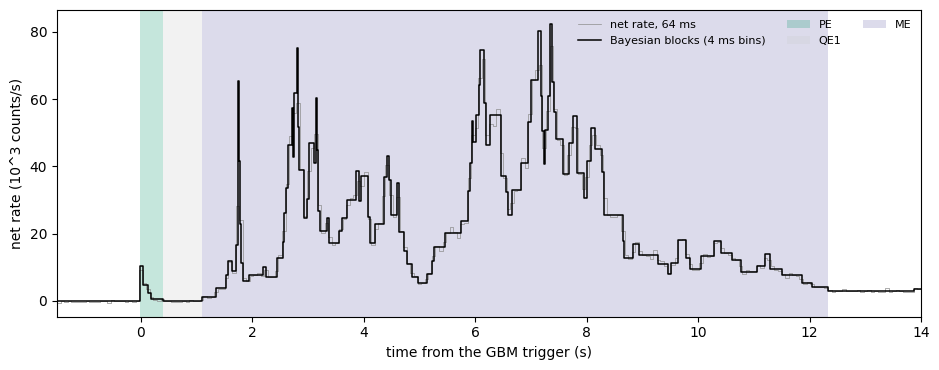

In [4]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
show = (lc.edges[:-1] > -1.5) & (lc.edges[:-1] < 14)
step = max(1, int(round(0.064 / row.Tres)))
edges = lc.edges[:-1][show][::step]
net = np.add.reduceat((lc.counts - lc.background)[show], np.arange(0, show.sum(), step)) / (step * row.Tres)
ax.step(edges, net / 1e3, where="post", lw=0.5, color="0.55", label="net rate, 64 ms")
b = blocks[(blocks.stop > -1.5) & (blocks.start < 14)]
ax.step(np.r_[b.start.values, b.stop.values[-1]], np.r_[b.rate.values, b.rate.values[-1]] / 1e3, where="post", color="k", lw=1.1,
        label=f"Bayesian blocks ({row.Tres * 1000:g} ms bins)")
for span, colour, label in ((found.pe, "#1b9e77", "PE"), (found.qe1, "0.8", "QE1"), (found.me, "#7570b3", "ME")):
    if span:
        ax.axvspan(*span, color=colour, alpha=0.25, lw=0, label=label)
ax.set_xlim(-1.5, 14); ax.set_xlabel("time from the GBM trigger (s)"); ax.set_ylabel("net rate (10^3 counts/s)")
ax.legend(frameon=False, fontsize=8, ncol=3)
fig.tight_layout(); fig.savefig(FIGURES / "00_episodes.png", dpi=140); plt.show()

Under their rule as written, GRB 211211A's blocks give exactly the four numbers of their table: a precursor of 0.424 s, a quiet gap of
0.692 s, a main emission of 11.236 s, and T_MVT,PE = 14 ms, which is the rise of the precursor's shortest pulse to the centre of its
brightest bin. It's a clean case: the precursor (green) is a single bright pulse, the gap (grey) sits at the background level for 0.7 s,
and the main emission (purple) is long and very variable, so there is only one way to read the blocks.

## 5. One spectral fit: the precursor

The spectrum of the precursor window in each detector (counts in each channel minus the background polynomial integrated over the window)
is fitted by forward folding: a photon model is passed through each detector's response to predict counts, and the parameters are those
that make the observed counts most likely (Poisson likelihood, with the background's own error). Five models are fitted (power law,
Comptonized, Band, blackbody, and the two-break model of notebook 14) and the rule of notebook 14 picks between them by the change in the
fit statistic. The plot shows the counts and the Comptonized model folded through the responses.

In [5]:
from grbtool.fitting import all_spectra, choose_model, fit_all_models, window_data
from grbtool.windows import Window
from spectral_fit_tools import cstat

window = Window("PE", [tuple(found.pe)], "precursor")
spectra, _ = all_spectra(gbm, [window])
data = window_data(gbm, window, spectra)
fits = fit_all_models(data)
chosen, _ = choose_model(fits)
names = {"pl": "power law", "cpl": "Comptonized", "band": "Band", "bb": "blackbody", "lowbreak": "two-break"}
print("chosen:", names[chosen])
pd.DataFrame({"C-stat": {names[m]: cstat(f) for m, (_, f) in fits.items()},
              "free parameters": {names[m]: len(f.parameters) for m, (_, f) in fits.items()}}).round(1)

chosen: Comptonized


,C-stat,free parameters
Band,380.4,4
Comptonized,384.1,3
two-break,377.3,6
power law,440.7,2
blackbody,497.6,2


Comptonized: E_peak 65.9 keV, alpha -1.08


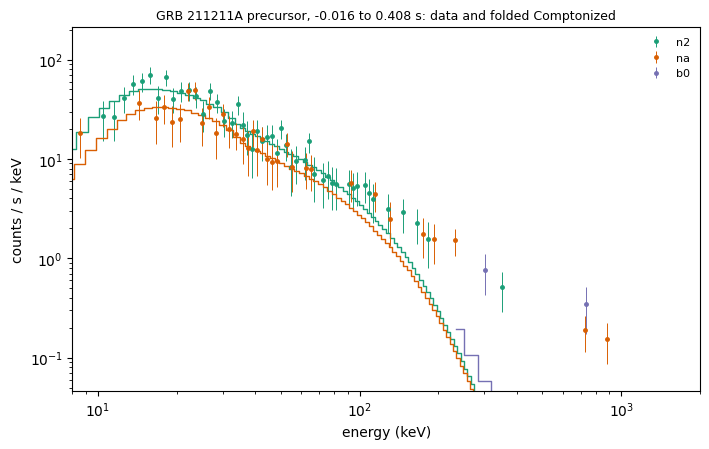

the batch's row for the same window: {'model': 'Comptonized', 'Epeak': 65.94452263039038, 'Epeak_err_lo': 5.233141571122346, 'Epeak_err_hi': 6.281664425517448}


In [6]:
function, fit = fits["cpl"]
amplitude, e_peak, alpha = fit.parameters
print(f"Comptonized: E_peak {e_peak:.1f} keV, alpha {alpha:.2f}")
energy, energy_err, counts, counts_err, upper = fit.data_count_spectrum()
model = fit.model_count_spectrum()
fig, ax = plt.subplots(figsize=(7.2, 4.6))
colours = ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#a6761d"]
for det, e, c, s, u, m, colour in zip(gbm.detectors, energy, counts, counts_err, upper, model, colours):
    ok = ~np.asarray(u, bool)                       # channels with a 2-sigma upper limit only are left out of the plot
    ax.errorbar(e[ok], c[ok], yerr=s[ok], fmt="o", ms=2.5, lw=0.7, color=colour, label=det)
    ax.step(m.centroids, m.rates_per_kev, where="mid", color=colour, lw=1.0)
# the precursor's counts lie below about 2 MeV; above that the BGO channels are consistent with zero and the Comptonized's cut-off
# sends the model down by hundreds of decades, so the plot stops at 2 MeV and its height is set by the data
shown = np.concatenate([c[~np.asarray(u, bool) & (e < 2000)] for e, c, u in zip(energy, counts, upper)])
shown = shown[shown > 0]
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(8, 2000); ax.set_ylim(0.3 * shown.min(), 3 * shown.max())
ax.set_xlabel("energy (keV)"); ax.set_ylabel("counts / s / keV")
ax.set_title(f"GRB {NAME} precursor, {found.pe[0]:.3f} to {found.pe[1]:.3f} s: data and folded Comptonized", fontsize=9)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "00_precursor_fit.png", dpi=140); plt.show()
saved_episodes, saved_spectra = G.saved(NAME)
if saved_spectra is not None:
    print("the batch's row for the same window:", saved_spectra.loc["PE", ["model", "Epeak", "Epeak_err_lo", "Epeak_err_hi"]].to_dict())

The rule keeps the Comptonized. Band lowers the fit statistic by only 3.7 for one more parameter (the rule asks for 9, and a tail steeper
than -2), and the two-break model by another 3.1 for two more (it asks for 11.8 and a clean break). The power law and the blackbody are far
worse (C-stat 440.7 and 497.6 against 384.1), so the spectrum is curved and peaked. The precursor's E_peak is 65.9 keV with alpha = -1.08,
the same as the batch's own fit of this window (65.9, -5.2/+6.3 keV). The folded model follows the counts of both NaI detectors from 8 keV
to a few hundred keV, and the BGO sees almost nothing: a soft precursor.

## 6. Joining E_peak with the variability timescale: GRB 230307A

The minimum variability timescale (MVT) is the shortest time over which the light curve changes more than counting noise allows; a
shorter MVT means a smaller or faster-changing emitting region. The join is by window: the same label and the same edges in both tables,
never by similar times (`shared/README.md`). Here E_peak (notebook 12) is joined with Dichiara et al.'s (2023) published MVTs, which is
what `shared/epeak_mvt_230307A.csv` holds; Rodrigo's own Haar-wavelet MVTs join the same way, window by window, and are his to publish.

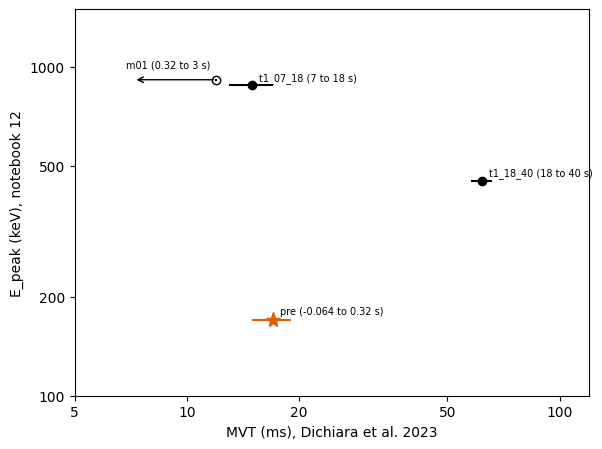

,label,t_start,t_stop,Epeak_keV,Epeak_err_lo,Epeak_err_hi,mvt_s,mvt_source
0,pre,-0.064,0.32,170.300,5.31000,5.31263,0.017,Dichiara et al. (2023) Table 1
1,m01,0.320,3.00,914.041,5.24692,5.27948,0.012,Dichiara et al. (2023) Table 1
2,t1_07_18,7.000,18.00,878.369,3.50150,3.54777,0.015,Dichiara et al. (2023) Table 1
3,t1_18_40,18.000,40.00,450.296,4.14921,4.46215,0.062,Dichiara et al. (2023) Table 1


In [7]:
joint = pd.read_csv("shared/epeak_mvt_230307A.csv")
fig, ax = plt.subplots(figsize=(6.2, 4.6))
for r in joint.itertuples():
    colour, marker, size = ("#d95f02", "*", 11) if r.label == "pre" else ("k", "o", 6)
    x = 1000 * r.mvt_s
    if str(r.upper_limit).lower() == "true" or not np.isfinite(r.mvt_err_lo_s):
        # an upper limit on the MVT: an open marker at the limit and an arrow towards shorter times, never a point with an error bar
        ax.errorbar(x, r.Epeak_keV, yerr=[[r.Epeak_err_lo], [r.Epeak_err_hi]], fmt=marker, ms=size, mfc="none", color=colour)
        ax.annotate("", xy=(0.6 * x, r.Epeak_keV), xytext=(x, r.Epeak_keV), arrowprops=dict(arrowstyle="->", color=colour))
    else:
        ax.errorbar(x, r.Epeak_keV, xerr=1000 * r.mvt_err_lo_s, yerr=[[r.Epeak_err_lo], [r.Epeak_err_hi]], fmt=marker, ms=size,
                    color=colour)
    # the upper limit's label goes above its arrow, so that it doesn't run into the 7-18 s window's label next to it
    above = str(r.upper_limit).lower() == "true"
    ax.annotate(f"{r.label} ({r.t_start:g} to {r.t_stop:g} s)", (1000 * r.mvt_s, r.Epeak_keV), xytext=(-4, 9) if above else (5, 4),
                ha="right" if above else "left", textcoords="offset points", fontsize=7)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(5, 120); ax.set_ylim(100, 1500)
ax.set_xticks([5, 10, 20, 50, 100], ["5", "10", "20", "50", "100"]); ax.set_yticks([100, 200, 500, 1000], ["100", "200", "500", "1000"])
ax.minorticks_off()
ax.set_xlabel("MVT (ms), Dichiara et al. 2023"); ax.set_ylabel("E_peak (keV), notebook 12")
fig.tight_layout(); fig.savefig(FIGURES / "00_epeak_mvt.png", dpi=140); plt.show()
joint[["label", "t_start", "t_stop", "Epeak_keV", "Epeak_err_lo", "Epeak_err_hi", "mvt_s", "mvt_source"]]

The precursor (orange star: 170 keV, 17 ms) sits far below the main-emission windows, which peak at 880-910 keV and vary in 15 ms or less
(m01's MVT is only an upper limit, 12 ms: the open circle with the arrow), before the emission softens to 450 keV and slows to 62 ms in
18-40 s. So the precursor varies about as fast as the bright main emission but is about five times softer. That soft and fast
combination is what the E_peak-MVT plane of the project is about. The plane only means something because each point's two numbers come
from the same window.

## 7. Zhu et al. measured again

All 111 bursts of the sample (`shared/zhu_sample.csv`: every Type I burst of their table, the confirmed mergers and collapsars, the
bursts near their line, and random others) were measured from the photons by the batch (`python -m zhu.run batch`), every number with an
error from 40 simulated light curves. Here are our zhu2026 numbers against their Table 1.

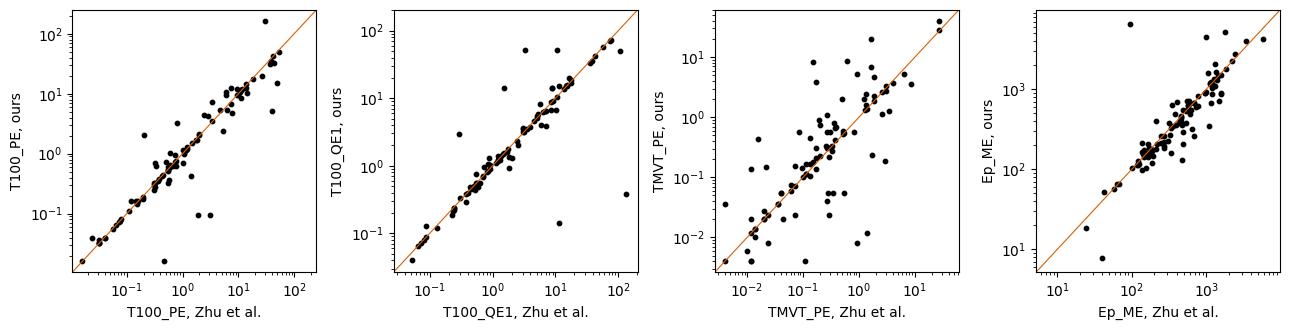

110 bursts measured


,number,bursts,median_dex,within_0_05_dex,within_0_2_dex
0,T100_PE,96,0.00,0.59,0.78
1,T100_QE1,96,0.00,0.66,0.90
2,TMVT_PE,96,0.00,0.27,0.52
3,Ep_ME,109,-0.02,0.45,0.83


In [8]:
ours = collect("zhu2026")
labels = L.label_table(ours.index, table.Type)
ours = ours.join(labels).join(epi_summary(ours, way="zhu"))
pairs = [("T100_PE", "T100_PE"), ("T100_QE1", "T100_QE1"), ("TMVT_PE", "TMVT_PE"), ("Ep_ME_zhu", "Ep_ME")]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
rows = []
for ax, (mine, theirs) in zip(axes, pairs):
    both = pd.DataFrame({"ours": ours[mine], "theirs": table.loc[ours.index, theirs]}).dropna()
    both = both[(both > 0).all(axis=1)]
    dex = np.log10(both.ours / both.theirs)
    rows.append(dict(number=theirs, bursts=len(both), median_dex=dex.median(), within_0_05_dex=(dex.abs() < 0.05).mean(),
                     within_0_2_dex=(dex.abs() < 0.2).mean()))
    ax.scatter(both.theirs, both.ours, s=10, color="k")
    lim = [both.min().min() / 1.5, both.max().max() * 1.5]
    ax.plot(lim, lim, color="#d95f02", lw=0.8)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel(f"{theirs}, Zhu et al."); ax.set_ylabel(f"{theirs}, ours")
fig.tight_layout(); fig.savefig(FIGURES / "00_zhu_reproduced.png", dpi=140); plt.show()
print(len(ours), "bursts measured")
pd.DataFrame(rows).round(2)

The precursor's duration and the gap after it come back well: within 0.2 dex of their Table 1 for 78% and 90% of the bursts with a
precursor, and E_p,ME fitted their way for 83% within 0.2 dex. T_MVT,PE scatters most, and not because of a
mistake: inside a one-block precursor the brightest bin is wherever counting noise puts it (notebook 23). The points far from the line
are listed with their causes in notebooks 23 and 24 (a different gap, a different start, the extended emission split differently).

## 8. The population table

Everything measured for every burst is in one file, `shared/zhu_remeasured.csv` (written by notebook 25; column names and units in its
header): durations and MVTs with their 16-84% ranges, E_p of the precursor and main emission both ways with errors or 95% intervals,
lags, EPI with its uncertainty, and the status of each number.

In [9]:
final = pd.read_csv("shared/zhu_remeasured.csv", comment="#", index_col=0)
print(final.shape[0], "bursts,", final.shape[1], "columns")
final.loc[[n for n in ("211211A", "230307A", "090618A", "190114C") if n in final.index]].iloc[:, :12]

111 bursts, 72 columns


,trigger,sample_group,status,status_reason,episode_reasons,Tres_s,PE_start_s,PE_stop_s,ME_start_s,ME_stop_s,EE_start_s,EE_stop_s
name,,,,,,,,,,,,
211211A,bn211211549,z25,complete,NaN,qe2: first dip after the main peak of 385 bins...,0.004,-0.016,0.408,1.100,12.336,13.876,81.896
230307A,bn230307656,z25,complete,NaN,qe2: first dip after the main peak of 109 bins...,0.004,NaN,NaN,-0.020,18.080,18.516,131.632
090618A,bn090618353,z25,complete,NaN,qe2: first dip after the main peak of 677 bins...,0.008,-0.632,34.088,49.416,99.144,104.560,157.456
190114C,bn190114873,z25,complete,NaN,qe2: first dip after the main peak of 168 bins...,0.016,-5.712,-1.456,-0.144,12.752,15.440,137.088


## 9. The baseline: EPI from our own numbers

EPI from our measurements, with E_p,ME fitted their way, against their types. Their types come from a clustering of their nine numbers,
so they are candidate labels; only a handful of bursts here have a confirmed origin (a kilonova or a supernova).

95 bursts with EPI; area under the ROC curve 0.982; balanced accuracy at 6.2: 0.921


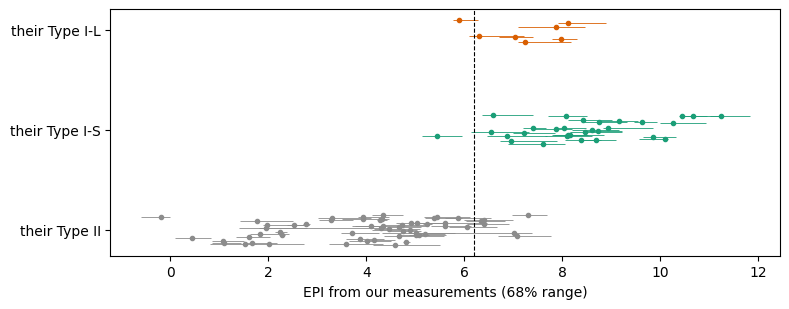

In [10]:
has = ours.EPI_zhu.notna()
y = ours.candidate_merger[has]
above = ours.EPI_zhu[has] > EPI_LINE
print(f"{int(has.sum())} bursts with EPI; area under the ROC curve {L.auc(ours.EPI_zhu[has], y):.3f}; balanced accuracy at {EPI_LINE}: "
      f"{0.5 * (above[y].mean() + (~above[~y]).mean()):.3f}")
fig, ax = plt.subplots(figsize=(8, 3.2))
for k, (kind, colour) in enumerate((("II", "0.55"), ("I-S", "#1b9e77"), ("I-L", "#d95f02"))):
    sel = has & (ours.zhu_type == kind)
    ax.errorbar(ours.EPI_zhu[sel], np.full(sel.sum(), k) + np.random.default_rng(k).uniform(-0.15, 0.15, sel.sum()),
                xerr=[ours.EPI_zhu[sel] - ours.EPI_p16_zhu[sel], ours.EPI_p84_zhu[sel] - ours.EPI_zhu[sel]], fmt="o", ms=3, lw=0.6,
                color=colour)
ax.axvline(EPI_LINE, color="k", ls="--", lw=0.8)
ax.set_yticks([0, 1, 2], ["their Type II", "their Type I-S", "their Type I-L"])
ax.set_xlabel("EPI from our measurements (68% range)")
fig.tight_layout(); fig.savefig(FIGURES / "00_epi.png", dpi=140); plt.show()

From our measurements EPI still separates their types well (area under the ROC curve 0.98), and the error bars show why
some bursts can't be placed: a burst whose 68% range crosses 6.2 has no settled side. Most of that range comes from T_MVT,PE.

## 10. The precursor's spectrum, three populations kept apart

Confirmed mergers (a kilonova), confirmed collapsars (a supernova), merger candidates (their Type I without a kilonova; never treated as
confirmed) and the rest (their Type II). Filled: precursor E_p measured by our rule. Not measured: a line over its 95% interval where
the interval is closed, or an open triangle at the bound, pointing to the open side, where it is bounded on one side only. GRB 230307A has no precursor under the zhu2026 rule as written (notebook 23), so
its open star uses notebook 12's window and their EPI and is never put into a test. Notebook 26 has the full version.

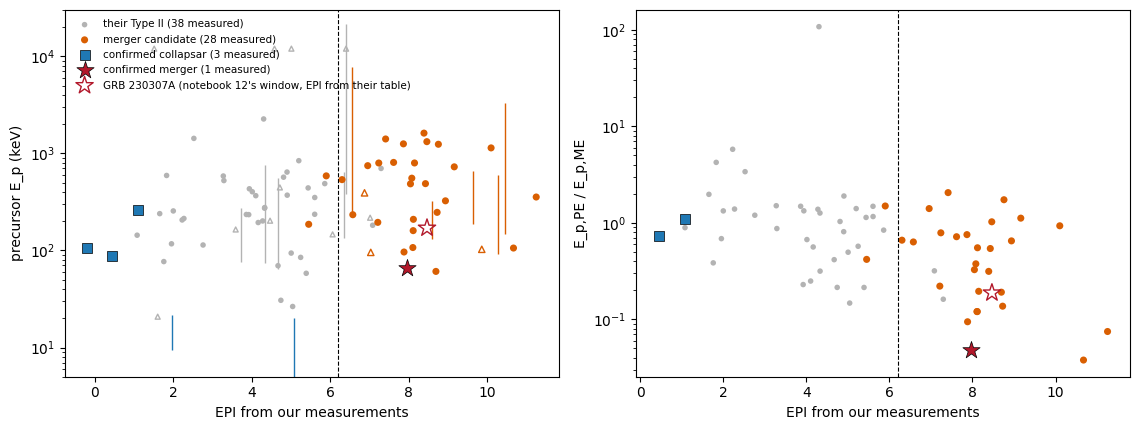

,bursts,precursor E_p measured,"median E_p,PE (keV)","median E_p,PE / E_p,ME"
confirmed collapsar,5,3,105.55,0.91
confirmed merger,2,1,65.94,0.05
merger candidate,41,29,487.73,0.55
their Type II,62,38,247.32,0.96


In [11]:
from zhu.laws import CONFIRMED
pop = pd.Series("their Type II", index=ours.index)
pop[ours.zhu_type.astype(str).str.startswith("I-")] = "merger candidate"
pop[[n for n, o in CONFIRMED.items() if o == "merger" and n in pop.index]] = "confirmed merger"
pop[[n for n, o in CONFIRMED.items() if o == "collapsar" and n in pop.index]] = "confirmed collapsar"
style = {"their Type II": ("0.7", "o", 16), "merger candidate": ("#d95f02", "o", 26), "confirmed collapsar": ("#1f78b4", "s", 60),
         "confirmed merger": ("#b2182b", "*", 170)}
measured = ours.measured_PE.astype(str) == "True"
both = measured & (ours.measured_ME.astype(str) == "True")      # a ratio needs both E_peak measured
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for name, (colour, marker, size) in style.items():
    sel = (pop == name) & has
    m = sel & measured
    axes[0].scatter(ours.EPI_zhu[m], ours.Ep_PE_ours[m], c=colour, marker=marker, s=size, edgecolors="k" if size > 50 else "none", lw=0.5,
                    label=f"{name} ({int(m.sum())} measured)", zorder=3 if size > 50 else 2)
    axes[1].scatter(ours.EPI_zhu[m & both], (ours.Ep_PE_ours / ours.Ep_ME_ours)[m & both], c=colour, marker=marker, s=size,
                    edgecolors="k" if size > 50 else "none", lw=0.5, zorder=3 if size > 50 else 2)
    # not measured: a 95% interval bounded both ways is a line, one bounded on one side only is a limit (a triangle pointing the open way)
    lo, hi = ours.Ep_PE_cpl_limit_lo.clip(upper=1.2e4), ours.Ep_PE_cpl_limit_hi.clip(lower=12.0)   # bounds beyond 5 keV-30 MeV at the edge
    bounded = sel & ~measured & lo.notna() & hi.notna()
    axes[0].vlines(ours.EPI_zhu[bounded], lo[bounded], hi[bounded], color=colour, lw=1.0)
    upper = sel & ~measured & lo.isna() & hi.notna()
    axes[0].scatter(ours.EPI_zhu[upper], hi[upper], facecolors="none", edgecolors=colour, marker="v", s=size * 0.8)
    lower = sel & ~measured & lo.notna() & hi.isna()
    axes[0].scatter(ours.EPI_zhu[lower], lo[lower], facecolors="none", edgecolors=colour, marker="^", s=size * 0.8)
if "230307A" in ours.index and not measured.get("230307A", False):
    # no precursor under the zhu2026 rule as written (notebook 23), so notebook 12's window, EPI from their table: drawn apart, never tested
    from zhu.catalogue import epi
    pre = pd.read_csv("shared/epeak_230307A.csv", comment="#").set_index("label").loc["pre"]
    t = table.loc["230307A"]
    x = float(epi(t.Ep_ME, t.T100_PE, t.T100_QE1, t.TMVT_PE))
    for ax, value in ((axes[0], pre.Epeak_keV), (axes[1], pre.Epeak_keV / ours.Ep_ME_ours["230307A"])):
        ax.scatter([x], [value], marker="*", s=170, facecolors="none", edgecolors="#b2182b", lw=1.0, zorder=4,
                   label="GRB 230307A (notebook 12's window, EPI from their table)" if ax is axes[0] else None)
axes[0].set_ylim(5, 3e4)
for ax, label in ((axes[0], "precursor E_p (keV)"), (axes[1], "E_p,PE / E_p,ME")):
    ax.set_yscale("log"); ax.axvline(EPI_LINE, color="k", ls="--", lw=0.8)
    ax.set_xlabel("EPI from our measurements"); ax.set_ylabel(label)
axes[0].legend(frameon=False, fontsize=7.5, loc="upper left")
fig.tight_layout(); fig.savefig(FIGURES / "00_precursor_spectrum.png", dpi=140); plt.show()
ratio = (ours.Ep_PE_ours / ours.Ep_ME_ours)[both]
pd.DataFrame({"bursts": pop.value_counts(), "precursor E_p measured": pop[measured].value_counts(),
              "median E_p,PE (keV)": ours.Ep_PE_ours[measured].groupby(pop).median(),
              "median E_p,PE / E_p,ME": ratio.groupby(pop[both]).median()}).round(2)

## 11. Does the precursor's spectrum add anything?

On the bursts with every number, logistic models with EPI alone and with log E_p,PE or the log ratio added, each scored on the bursts it
wasn't fitted to (repeated 5-fold cross-validation, log loss), and compared with the same model given a shuffled copy of the new column
(a permutation test: p is the share of shuffles that do as well). Then E_p,PE added to EPI's four inputs as separate columns: if a hard
precursor simply goes with a hard main emission, E_p,PE adds nothing once E_p,ME is there.

In [12]:
X = L.inputs(ours)
X["EPI"] = ours.EPI_zhu
X["ratio"] = X.Ep_PE - X.Ep_ME
use = X.dropna(subset=["EPI", "Ep_PE", "Ep_ME", "T_PE", "T_QE1", "MVT_PE"])
use = use[both[use.index]]                     # both E_peak measured, as in notebook 26
y_use = ours.candidate_merger[use.index]
rows = []
# 100 shuffles each so that this runs in a few minutes; notebook 26 has these and more with 200
for base, extra in ((["EPI"], "Ep_PE"), (["EPI"], "ratio"), (["T_PE", "T_QE1", "MVT_PE", "Ep_ME"], "Ep_PE")):
    gain, _, p = L.permutation_test(use, y_use, base, extra, permutations=100)
    rows.append(dict(model=" + ".join(base), added=extra, gain_in_log_loss=gain, permutation_p=p))
print(len(use), "bursts:", int(y_use.sum()), "candidate mergers,", int((~y_use).sum()), "candidate collapsars")
pd.DataFrame(rows).round(4)

69 bursts: 29 candidate mergers, 40 candidate collapsars


,model,added,gain_in_log_loss,permutation_p
0,EPI,Ep_PE,-0.0051,0.5347
1,EPI,ratio,-0.0074,0.7327
2,T_PE + T_QE1 + MVT_PE + Ep_ME,Ep_PE,-0.0017,0.3465


Adding the precursor's E_peak or its ratio to EPI makes the prediction for bursts left out no better than a shuffled copy of the same
column does (permutation p = 0.53 and 0.73), and neither does adding E_p,PE to all four of EPI's inputs (p = 0.35). Notebook 26 runs
these with more shuffles, puts the limits in, and shows why: the precursor's E_peak follows the main emission's, which EPI already holds.

## 12. Systematics and limits

The numbers that limit the result, each from its own notebook: the statistical part of EPI's uncertainty, input by input (25); how much
the precursor's T_MVT can move inside one Bayesian block (23); GBM's energy scale against GECAM (15).

In [13]:
half = lambda lo, hi: 0.5 * (np.log10(hi) - np.log10(lo))
budget = pd.Series({
    "E_p,ME (counts twice)": 2 * (0.5 * (np.log10(ours.Ep_ME_zhu + ours.Ep_ME_zhu_hi) - np.log10(ours.Ep_ME_zhu - ours.Ep_ME_zhu_lo))).median(),
    "T100,PE": half(ours.T100_PE_p16, ours.T100_PE_p84).median(),
    "T100,QE1 (counts half)": 0.5 * half(ours.T100_QE1_p16, ours.T100_QE1_p84).median(),
    "T_MVT,PE": half(ours.TMVT_PE_p16, ours.TMVT_PE_p84).median(),
    "GBM energy scale, 10% in E_p,ME": 2 * np.log10(1.1)})
print("median contribution to EPI's uncertainty (dex):")
print(budget.round(3).to_string())

median contribution to EPI's uncertainty (dex):
E_p,ME (counts twice)              0.106
T100,PE                            0.024
T100,QE1 (counts half)             0.007
T_MVT,PE                           0.329
GBM energy scale, 10% in E_p,ME    0.083


The main limits, each shown in its notebook: two confirmed long mergers only (26); candidate labels that come from a clustering of the
same numbers (22, 26); the precursor's T_MVT, which inside a single block is wherever the counting noise puts the brightest bin (23); the
model dependence of E_p (GRB 211211A: Band against the two-break model, a factor of about 2; 14, 24); GBM's telemetry limit and pile-up in
the brightest bursts (15); faint precursors whose E_p is only a 95% interval (24, 26).

## 13. Swift/BAT as an independent check

19 bursts of the sample are in the Swift/BAT GRB catalogue and 18 have BAT event data (15-150 keV, a coded mask, notebook 27). The BAT
chain is checked against the BAT catalogue, then BAT's own light curve gives the episodes again, on GBM's time axis (the trigger times and the light-travel time between
the two spacecraft).

In [14]:
bat = Path("results/bat")
if (bat / "validation.csv").exists() and (bat / "episodes_vs_gbm.csv").exists():
    v = pd.read_csv(bat / "validation.csv")
    v["difference"] = v["index"] - v.catalogue_index
    print("power-law index against the BAT catalogue:", len(v), "fits, median difference", round(v.difference.median(), 3),
          ", largest", round(v.difference.abs().max(), 3))
    e = pd.read_csv(bat / "episodes_vs_gbm.csv")
    print(e[e.episode.isin(["pe", "me"])].groupby("episode")[["d_start", "d_stop"]].agg(["count", "median"]).round(3).to_string())
else:
    print("results/bat/ is not here: run python -m instruments.bat_compare (notebook 27)")

power-law index against the BAT catalogue: 30 fits, median difference -0.052 , largest 0.288
        d_start        d_stop       
          count median  count median
episode                             
me           16 -0.004     16  0.362
pe           12  0.004     12 -0.215


The BAT chain gives the catalogue's power-law indices to a median of 0.05 (the largest difference, 0.29, is GRB 190829A's brightest
second, seen at 4% partial coding). Once the light-travel time is in, BAT's main emission starts within a median 4 ms of GBM's over 16
bursts. In notebook 27, BAT's precursor spectra are what GBM's fits predict for 10 of 11 precursors; the exception is GRB 090618's long
precursor.

## 14. What it means physically

Measured: (1) Zhu et al.'s bursts measured again from the photons with their rules: their precursor and gap come back within 0.2 dex for 78% and
90% of the bursts, GRB 211211A exactly. Their T_MVT is the rise to the brightest bin, which inside a one-block precursor is counting noise
of about 0.4 dex, the largest part of EPI's uncertainty. (2) EPI from our numbers separates their types (area 0.98), and the confirmed
bursts fall where their origin says. (3) The precursor's E_peak adds nothing to EPI: it follows the main emission's E_peak. (4) The two
confirmed long mergers have precursors far softer than their main emission (0.05 and 0.19), but two bursts can't make a test;
about four, against ten supernova collapsars, would. (5) Swift/BAT agrees with GBM wherever the two can be compared, except for GRB
090618's long precursor.

Interpretation (labelled as such): A merger-like burst in Zhu et al.'s sense has a short precursor that varies quickly and a hard main emission. A precursor is hard when
its burst is hard, so its peak energy says little about the progenitor on its own. The precursors of GRB 211211A and 230307A, about twenty
and five times softer than their main emissions, are what light from the last moments before a merger, before the jet, might look like
(for a crust shattered by a tidal resonance, GRB 211211A's needs about the fiducial energy release), but two events are a hint, not a
pattern. Kilonova searches of the merger candidates, and gravitational-wave detections with a precursor, are what could test it.

In [15]:
from zhu import physics as P
print(f"two 1.4 solar-mass neutron stars reach 100 Hz in gravitational waves {P.inspiral_time(100.0):.1f} s before merging")
if found.pe and found.me:
    delay = found.me[0] - found.pe[0]
    print(f"GRB {NAME}: precursor start to main-emission start {delay:.2f} s; light can cross c T_MVT,PE = "
          f"{P.light_size_km(d['TMVT_PE']):.0f} km in the precursor's MVT (no beaming)")

two 1.4 solar-mass neutron stars reach 100 Hz in gravitational waves 2.2 s before merging
GRB 211211A: precursor start to main-emission start 1.12 s; light can cross c T_MVT,PE = 4197 km in the precursor's MVT (no beaming)
